# Exploración de datos (EDA) – Airbnb Bogotá, junio 2026

**Taller evaluativo 2 – Proceso ETL · Inteligencia de Negocios (ITM)**

Objetivo: entender la estructura y la calidad de las colecciones `Listings`, `Reviews` y `Calendar` **leídas desde MongoDB local**
con la clase `Extraccion` (`src/extraccion.py`), y justificar con evidencia cada decisión de la clase `Transformacion`.
Este notebook **solo explora**: la transformación formal vive en `src/transformacion.py` y se ejecuta con `python -m src.pipeline`.

| Sección del enunciado | Contenido |
|---|---|
| 2.1 Entendimiento de los datos | `head()`, `shape`, `info()`, tipos tal como llegan de MongoDB, variables relevantes |
| 2.2 Calidad de los datos | nulos, duplicados, integridad, atípicos de `price`, `minimum_nights`, `availability_365` |
| 2.3 Transformaciones necesarias | moneda, fechas, texto, `amenities`, información del anfitrión, calendario por mes y semana, rangos de precio |
| 2.4 Hallazgos | correlaciones, precio por tipo de habitación y barrio, reseñas en el tiempo, decisiones para el ETL |

**Requisitos para ejecutarlo:** `mongod` corriendo con la base `airbnb_bogota` poblada (`python scripts/cargar_mongodb.py`),
y JupyterLab abierto con `.venv\Scripts\python -m jupyterlab` desde la raíz del proyecto. Las figuras se guardan en `notebooks/figuras/`
para el informe.

> Las interpretaciones se escribieron a partir de la ejecución contra MongoDB local del 11 de octubre de 2026 (datos de Inside Airbnb,
> corte del 21 de junio de 2026).

In [1]:
import sys
from pathlib import Path

# Permite importar src/ tanto si el kernel arranca en notebooks/ como en la raíz del proyecto.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import FACTOR_IQR_ATIPICOS, PRECIO_CORTES, PRECIO_ETIQUETAS, UMBRAL_MINIMO_NOCHES
from src.extraccion import Extraccion
from src.transformacion import limpiar_precio, limpiar_texto, marcar_atipicos_iqr, parsear_amenities

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

FIGURAS = RAIZ / "notebooks" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
COP = mticker.FuncFormatter(lambda x, _: f"${x:,.0f}")


def guardar(fig, nombre):
    """Guarda la figura en notebooks/figuras/ para usarla en el informe."""
    fig.savefig(FIGURAS / f"{nombre}.png", dpi=150, bbox_inches="tight")


def existentes(df, columnas):
    """MongoDB omite los campos vacíos: se trabaja solo con las columnas que llegaron."""
    return [c for c in columnas if c in df.columns]

## 1. Extracción desde MongoDB

Se usa la misma clase del ETL. `validar_colecciones()` confirma que las tres colecciones existen y no están vacías, y cada
extracción queda registrada en el log de la ejecución (`logs/log_YYYYMMDD_HHMM.txt`).

- `Listings` y `Reviews` se leen completas.
- `Calendar` tiene ≈7 millones de documentos: se usa `extraer_calendario_mensual()` (agregación `$group` dentro de MongoDB por
  anuncio y mes, ≈249 mil filas) y una muestra diaria de 200 000 documentos para ver la estructura original.
  La muestra son los **primeros** documentos en orden de inserción (≈548 anuncios con su año completo), no una muestra aleatoria.

In [2]:
with Extraccion() as ext:
    conteos = ext.validar_colecciones()
    listings = ext.extraer_listings()
    reviews = ext.extraer_reviews()
    calendar_mensual = ext.extraer_calendario_mensual()
    calendar_muestra = ext.extraer_calendar(limite=200_000)

pd.DataFrame({
    "documentos en MongoDB": pd.Series(conteos),
    "esperado (archivo fuente)": pd.Series({"listings": 19_187, "reviews": 527_731, "calendar": 7_003_255}),
})

2026-10-11 22:00:08 | INFO    | etl_airbnb.extraccion | Conexión exitosa con MongoDB (mongodb://localhost:27017), base de datos 'airbnb_bogota'


2026-10-11 22:00:08 | INFO    | etl_airbnb.extraccion | Colección 'Listings': 19,187 documentos


2026-10-11 22:00:08 | INFO    | etl_airbnb.extraccion | Colección 'Reviews': 527,731 documentos


2026-10-11 22:00:08 | INFO    | etl_airbnb.extraccion | Colección 'Calendar': 7,003,255 documentos


2026-10-11 22:00:10 | INFO    | etl_airbnb.extraccion | Extracción de 'Listings': 19,187 registros, 77 columnas (1.8 s)


2026-10-11 22:00:19 | INFO    | etl_airbnb.extraccion | Extracción de 'Reviews': 527,731 registros, 6 columnas (9.2 s)


2026-10-11 22:00:28 | INFO    | etl_airbnb.extraccion | Extracción agregada de 'Calendar' (listing_id x mes): 249,431 registros (8.7 s)


2026-10-11 22:00:30 | INFO    | etl_airbnb.extraccion | Extracción de 'Calendar': 200,000 registros, 5 columnas (2.1 s)


2026-10-11 22:00:30 | INFO    | etl_airbnb.extraccion | Conexión con MongoDB cerrada


,documentos en MongoDB,esperado (archivo fuente)
listings,19187,19187
reviews,527731,527731
calendar,7003255,7003255


**Interpretación.** Los conteos de MongoDB deben coincidir con los registros de los archivos fuente (19 187 · 527 731 · 7 003 255).
Si coinciden, la importación quedó completa y lo que se analiza abajo es exactamente lo que recibirá el ETL.

## 2.1 Entendimiento de los datos

### Dimensiones de cada DataFrame

In [3]:
pd.DataFrame(
    {"filas": [len(listings), len(reviews), len(calendar_muestra), len(calendar_mensual)],
     "columnas": [listings.shape[1], reviews.shape[1], calendar_muestra.shape[1], calendar_mensual.shape[1]]},
    index=["listings", "reviews", "calendar (muestra diaria)", "calendar (agregado mensual)"],
)

,filas,columnas
listings,19187,77
reviews,527731,6
calendar (muestra diaria),200000,5
calendar (agregado mensual),249431,5


**Interpretación.** El archivo de anuncios tiene 90 columnas, pero `listings` llega con menos (≈77): la importación omite los
campos vacíos, de modo que las columnas que estaban 100 % vacías en el CSV no existen en ningún documento (se verifica en 2.2).

### Listings

In [4]:
listings.head(3).T

,0,1,2
id,27841,65762,138660
listing_url,https://www.airbnb.com/rooms/27841,https://www.airbnb.com/rooms/65762,https://www.airbnb.com/rooms/138660
scrape_id,20260621155658,20260621155658,20260621155658
last_scraped,2026-06-22,2026-06-22,2026-06-22
source,city scrape,city scrape,city scrape
...,...,...,...
calculated_host_listings_count_entire_homes,3,22,1
calculated_host_listings_count_private_rooms,0,2,0
calculated_host_listings_count_shared_rooms,0,0,0
reviews_per_month,0.24,0.19,0.14


In [5]:
listings.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 19187 entries, 0 to 19186
Data columns (total 77 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            19187 non-null  int64  
 1   listing_url                                   19187 non-null  str    
 2   scrape_id                                     19187 non-null  int64  
 3   last_scraped                                  19187 non-null  str    
 4   source                                        19187 non-null  str    
 5   name                                          19187 non-null  str    
 6   description                                   18664 non-null  str    
 7   picture_url                                   19187 non-null  str    
 8   host_id                                       19187 non-null  int64  
 9   host_url                                      19187 non-null  str    
 1

### Tipos tal como llegan de MongoDB

Se revisa el tipo Python de un documento: confirma qué hay que convertir en la transformación.

In [6]:
columnas_tipo = existentes(listings, ["id", "host_id", "price", "amenities", "host_is_superhost", "last_scraped",
                                      "first_review", "minimum_nights", "availability_365", "review_scores_rating"])
muestra_tipos = listings[columnas_tipo].dropna().iloc[0] if listings[columnas_tipo].dropna().shape[0] else listings[columnas_tipo].iloc[0]
pd.DataFrame({"ejemplo": muestra_tipos.astype(str).str[:60],
              "tipo en Python": muestra_tipos.map(lambda v: type(v).__name__)})

,ejemplo,tipo en Python
id,27841,int64
host_id,113734,int64
price,"$284,294.01",str
amenities,"[""Blender"", ""Luggage dropoff allowed"", ""Long t...",str
host_is_superhost,t,str
last_scraped,2026-06-22,str
first_review,2010-10-06,str
minimum_nights,28.0,float64
availability_365,82,int64
review_scores_rating,4.87,float64


**Interpretación.** `price` es **texto** con símbolo y separador de miles (`"$284,294.01"`), las fechas son texto `YYYY-MM-DD`,
`amenities` es una lista JSON guardada como texto y los booleanos vienen como `"t"`/`"f"`. Ninguno de esos campos sirve para
cálculos sin convertirlo: es la base de las transformaciones de la sección 2.3.

### Reviews y Calendar

In [7]:
reviews.head()

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,27841,113163,2010-10-06,121485,Paul,I really enjoyed staying at Marcela's place. I...
1,27841,143106,2010-11-22,288940,Vic,"I, Arrived an hour late from the airport. Mar..."
2,27841,172475,2011-01-19,98406,Matt,"Wonderful hosts, beautiful spacious apartment,..."
3,27841,225796,2011-04-13,471115,Tiffany,Marcela was a lovely and gracious host. She me...
4,27841,952928,2012-02-27,1098411,Sarah,Marcela is the perfect host and has a gorgeuos...


In [8]:
reviews.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 527731 entries, 0 to 527730
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   listing_id     527731 non-null  int64
 1   id             527731 non-null  int64
 2   date           527731 non-null  str  
 3   reviewer_id    527731 non-null  int64
 4   reviewer_name  527731 non-null  str  
 5   comments       527540 non-null  str  
dtypes: int64(3), str(3)
memory usage: 199.1 MB


In [9]:
calendar_muestra.head()

,listing_id,date,available,minimum_nights,maximum_nights
0,15410909,2026-06-22,f,2,1125
1,15410909,2026-06-23,f,2,1125
2,15410909,2026-06-24,f,2,1125
3,15410909,2026-06-25,t,2,1125
4,15410909,2026-06-26,t,2,1125


In [10]:
calendar_muestra.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   listing_id      200000 non-null  int64
 1   date            200000 non-null  str  
 2   available       200000 non-null  str  
 3   minimum_nights  200000 non-null  int64
 4   maximum_nights  200000 non-null  int64
dtypes: int64(3), str(2)
memory usage: 7.6 MB


In [11]:
calendar_mensual.head()

,dias_registrados,dias_disponibles,minimo_noches_promedio,listing_id,mes
0,9,0,28.00,27841,2026-06
1,31,0,28.00,27841,2026-07
2,31,0,28.00,27841,2026-08
3,30,0,28.00,27841,2026-09
4,31,0,28.00,27841,2026-10


### Variables relevantes

| Colección | Variable | Descripción | Uso en el análisis |
|---|---|---|---|
| Listings | `id` | Identificador del anuncio (hasta 19 dígitos) | Llave; se renombra `listing_id` |
| Listings | `host_id`, `host_*` | Datos del anfitrión, repetidos en cada anuncio | Se separan en la tabla `hosts` |
| Listings | `neighbourhood_cleansed` | Localidad de Bogotá | Precio y oferta por zona |
| Listings | `room_type`, `property_type`, `accommodates`, `bedrooms`, `bathrooms` | Características del alojamiento | Explican el precio |
| Listings | `price` | Precio por noche en COP (texto) | Variable principal; se limpia y se categoriza |
| Listings | `minimum_nights`, `availability_365` | Estadía mínima y días disponibles en el año | Atípicos y reglas de negocio |
| Listings | `amenities` | Lista JSON de servicios | Se desanida en `listing_amenities` |
| Listings | `number_of_reviews`, `review_scores_rating` | Demanda y satisfacción | Correlaciones |
| Reviews | `listing_id`, `id`, `date`, `reviewer_id`, `comments` | Una fila por reseña | Evolución de la demanda, calidad del texto |
| Calendar | `listing_id`, `date`, `available`, `minimum_nights`, `maximum_nights` | Un día por anuncio (365 días desde el 21-jun-2026); **no trae precio** | Disponibilidad por mes y semana |

## 2.2 Calidad de los datos

### Valores nulos

Los textos vacíos (`""`) se cuentan como nulos por si la colección se importó con otra herramienta (`mongoimport`, Compass).

In [12]:
# Columnas que en el archivo fuente están 100 % vacías: MongoDB no las guarda.
COLUMNAS_100_NULAS_CSV = [
    "neighborhood_overview", "host_since", "host_neighbourhood", "host_thumbnail_url", "host_acceptance_rate",
    "host_response_rate", "host_response_time", "host_verifications", "host_total_listings_count",
    "neighbourhood", "neighbourhood_group_cleansed", "calendar_updated", "instant_bookable",
]
ausentes = [c for c in COLUMNAS_100_NULAS_CSV if c not in listings.columns]
print(f"{len(ausentes)} de {len(COLUMNAS_100_NULAS_CSV)} columnas 100 % vacías no existen en la colección:")
print(", ".join(ausentes))


def tabla_nulos(df):
    vacios = df.replace(r"^\s*$", np.nan, regex=True)
    nulos = vacios.isna().sum()
    return (pd.DataFrame({"nulos": nulos, "pct": 100 * nulos / len(df)})
              .query("nulos > 0").sort_values("nulos", ascending=False))


nulos_listings = tabla_nulos(listings)
nulos_listings.head(25)

13 de 13 columnas 100 % vacías no existen en la colección:
neighborhood_overview, host_since, host_neighbourhood, host_thumbnail_url, host_acceptance_rate, host_response_rate, host_response_time, host_verifications, host_total_listings_count, neighbourhood, neighbourhood_group_cleansed, calendar_updated, instant_bookable


,nulos,pct
host_about,8799,45.86
host_location,5157,26.88
review_scores_checkin,4266,22.23
review_scores_location,4266,22.23
review_scores_value,4266,22.23
last_review,4265,22.23
first_review,4265,22.23
review_scores_accuracy,4265,22.23
review_scores_rating,4265,22.23
review_scores_cleanliness,4265,22.23


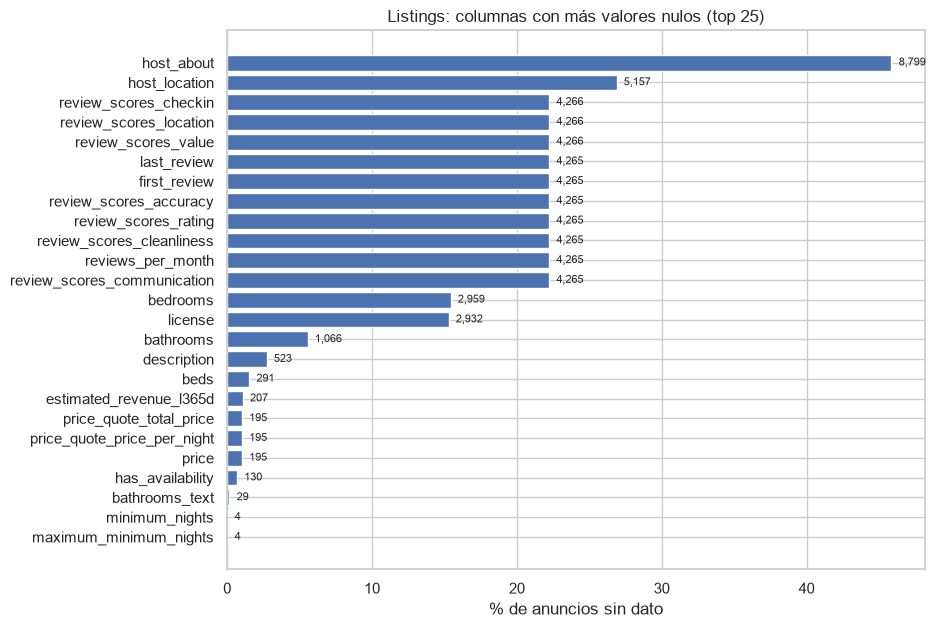

In [13]:
fig, ax = plt.subplots(figsize=(9, 7))
top = nulos_listings.head(25).iloc[::-1]
ax.barh(top.index, top["pct"], color="#4C72B0")
ax.set_xlabel("% de anuncios sin dato")
ax.set_title("Listings: columnas con más valores nulos (top 25)")
for y, (pct, n) in enumerate(zip(top["pct"], top["nulos"])):
    ax.text(pct + 0.5, y, f"{n:,}", va="center", fontsize=8)
guardar(fig, "01_nulos_listings")
plt.show()

**Interpretación.**
- 13 columnas están vacías en el 100 % de los anuncios (información del anfitrión que Inside Airbnb ya no publica,
  `neighbourhood`, `calendar_updated`, `instant_bookable`). No aportan nada: el ETL las descarta.
- `host_about` (≈8 799) y `host_location` (≈5 157) son texto descriptivo opcional: se rellenan con `"Sin información"`.
- `review_scores_*` (≈4 265) son nulos **estructurales**: corresponden a anuncios sin reseñas. Imputarlos con la media inventaría
  calificaciones, así que **no se imputan**. Lo mismo para `bedrooms` (≈2 959) y `bathrooms` (≈1 066).
- `price` falta en ≈195 anuncios (1 %). Se conservan con la etiqueta `"Sin precio"` porque siguen siendo oferta real
  (tienen calendario y reseñas); el análisis de precios los excluye.

In [14]:
print("Reviews – nulos por columna:")
display(tabla_nulos(reviews))
print("Calendar (muestra diaria) – nulos por columna:")
display(tabla_nulos(calendar_muestra))

Reviews – nulos por columna:


,nulos,pct
comments,191,0.04


Calendar (muestra diaria) – nulos por columna:


,nulos,pct


**Interpretación.** En `Reviews` solo faltan comentarios (191 reseñas sin texto, 0,04 %): la reseña existe, así que se conserva y se
marca con `sin_comentario = 1`. `Calendar` no tiene nulos relevantes en sus campos de disponibilidad.

### Duplicados e integridad referencial

In [15]:
duplicados = pd.Series({
    "listings: id repetido": listings["id"].duplicated().sum(),
    "listings: fila completa repetida": listings.duplicated().sum(),
    "reviews: id repetido": reviews["id"].duplicated().sum(),
    "reviews: fila completa repetida": reviews.duplicated().sum(),
    "calendar muestra: (listing_id, date) repetido": calendar_muestra.duplicated(["listing_id", "date"]).sum(),
    "calendar mensual: (listing_id, mes) repetido": calendar_mensual.duplicated(["listing_id", "mes"]).sum(),
    "reviews cuyo listing_id no está en Listings": (~reviews["listing_id"].isin(listings["id"])).sum(),
    "anuncios del calendario que no están en Listings": (~calendar_mensual["listing_id"].isin(listings["id"])).sum(),
    "anuncios de Listings sin calendario": (~listings["id"].isin(calendar_mensual["listing_id"])).sum(),
}, name="registros")
duplicados.to_frame()

,registros
listings: id repetido,0
listings: fila completa repetida,0
reviews: id repetido,0
reviews: fila completa repetida,0
"calendar muestra: (listing_id, date) repetido",0
"calendar mensual: (listing_id, mes) repetido",0
reviews cuyo listing_id no está en Listings,0
anuncios del calendario que no están en Listings,0
anuncios de Listings sin calendario,0


**Interpretación.** No hay duplicados por llave ni filas repetidas, y todas las reseñas y filas de calendario apuntan a un anuncio
existente. **No hay nada que eliminar hoy**, pero la deduplicación por llave y el filtro de huérfanos se mantienen en la
transformación como control: si una recarga de MongoDB duplica documentos, el ETL lo detecta, lo registra como WARNING en el log y
el índice único de SQLite impide cargar duplicados.

### Atípicos en `price`

In [16]:
precio = limpiar_precio(listings["price"]) if "price" in listings.columns else pd.Series(dtype="float64")
listings["precio_num"] = precio

percentiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
display(precio.describe(percentiles=percentiles).to_frame("precio por noche (COP)"))

q1, q3 = precio.quantile([0.25, 0.75])
iqr = q3 - q1
_, limite_3 = marcar_atipicos_iqr(precio, FACTOR_IQR_ATIPICOS)
limite_15 = q3 + 1.5 * iqr
print(f"Sin precio: {precio.isna().sum():,} anuncios ({precio.isna().mean():.1%})")
print(f"IQR×1.5 → límite ${limite_15:,.0f}: {(precio > limite_15).sum():,} anuncios")
print(f"IQR×{FACTOR_IQR_ATIPICOS:g} → límite ${limite_3:,.0f}: {(precio > limite_3).sum():,} anuncios (criterio del ETL)")

,precio por noche (COP)
count,"18,992.00"
mean,"446,026.55"
std,"8,829,056.71"
min,"19,181.11"
1%,"37,610.03"
5%,"55,504.63"
25%,"110,000.00"
50%,"161,460.00"
75%,"230,346.38"
95%,"497,579.69"


Sin precio: 195 anuncios (1.0%)
IQR×1.5 → límite $410,866: 1,410 anuncios
IQR×3 → límite $591,386: 659 anuncios (criterio del ETL)


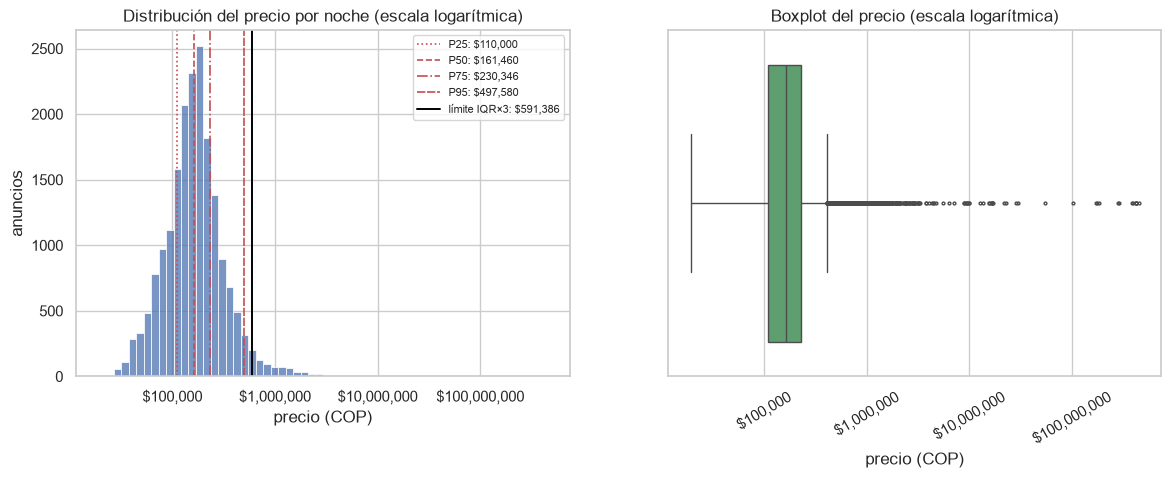

In [17]:
validos = precio.dropna()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(np.log10(validos), bins=60, ax=axes[0], color="#4C72B0")
estilos = zip(validos.quantile([0.25, 0.5, 0.75, 0.95]), ["P25", "P50", "P75", "P95"], [":", "--", "-.", (0, (5, 1))])
for p, etiqueta, estilo in estilos:
    axes[0].axvline(np.log10(p), color="#C44E52", ls=estilo, lw=1.2, label=f"{etiqueta}: ${p:,.0f}")
axes[0].axvline(np.log10(limite_3), color="black", lw=1.4, label=f"límite IQR×3: ${limite_3:,.0f}")
axes[0].legend(fontsize=8)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${10 ** x:,.0f}"))
axes[0].set(title="Distribución del precio por noche (escala logarítmica)", xlabel="precio (COP)", ylabel="anuncios")

sns.boxplot(x=validos, ax=axes[1], color="#55A868", fliersize=2)
axes[1].set_xscale("log")
axes[1].xaxis.set_major_formatter(COP)
axes[1].set(title="Boxplot del precio (escala logarítmica)", xlabel="precio (COP)")
plt.setp(axes[1].get_xticklabels(), rotation=30)
guardar(fig, "02_distribucion_precio")
plt.show()

In [18]:
columnas_caros = existentes(listings, ["id", "name", "room_type", "property_type", "accommodates", "bedrooms",
                                       "neighbourhood_cleansed", "minimum_nights", "number_of_reviews", "price"])
listings.nlargest(10, "precio_num")[columnas_caros + ["precio_num"]]

,id,name,room_type,property_type,accommodates,bedrooms,neighbourhood_cleansed,minimum_nights,number_of_reviews,price,precio_num
17185,1629245377389583455,casa Q Iuniq - Boutique,Entire home/apt,Entire rental unit,2,1.00,Chapinero,1.00,0,"$448,176,567.00","448,176,567.00"
17227,1631561754372485139,casa Q Iuniq- Boutique,Private room,Private room in rental unit,2,1.00,Chapinero,1.00,0,"$421,287,834.00","421,287,834.00"
17238,1632658392056259396,casa Q Iuniq - Boutique,Private room,Private room in rental unit,2,1.00,Chapinero,1.00,6,"$421,287,834.00","421,287,834.00"
17240,1632680823682299581,casa Q Iuniq - Boutique,Private room,Private room in loft,4,1.00,Chapinero,1.00,2,"$421,287,834.00","421,287,834.00"
17241,1632687908999942806,Casa Q Iuniq - Boutique,Private room,Private room in rental unit,2,1.00,Chapinero,1.00,6,"$418,047,397.00","418,047,397.00"
17243,1632693865280443336,casa Q Iuniq - Boutique,Private room,Private room in rental unit,2,1.00,Chapinero,1.00,1,"$388,883,464.00","388,883,464.00"
17239,1632670566895238267,casa Q Iuniq - Boutique,Private room,Private room in rental unit,2,1.00,Chapinero,1.00,0,"$385,643,027.00","385,643,027.00"
6967,872010695106019062,Habitación Cómoda,Private room,Private room in casa particular,1,NaN,Barrios Unidos,1.00,0,"$288,909,191.69","288,909,191.69"
6843,860199176293876612,descanso tu casa.,Private room,Private room in home,1,NaN,Barrios Unidos,30.00,0,"$280,048,351.19","280,048,351.19"
1692,29237840,Habitación Doble Privada en Hostal Yarumo,Private room,Private room in home,2,1.00,Candelaria,1.00,2,"$182,588,320.00","182,588,320.00"


**Interpretación.**
- El precio tiene una cola derecha muy larga: mediana 161 460 COP, P95 497 580, P99 ≈1,3 millones y un máximo de 448 millones
  por noche. Por eso la distribución solo es legible en escala logarítmica, donde se ve aproximadamente normal.
- Los precios más altos (entre 388 y 448 millones por noche) son **seis anuncios del mismo anfitrión** (“casa Q Iuniq - Boutique”,
  Chapinero), casi todos habitaciones privadas para 2 personas: es un error de captura evidente, no un alojamiento de lujo.
- Con el criterio clásico IQR×1.5 se marcarían 1 410 anuncios (por encima de 410 866 COP), muchos de ellos alojamientos grandes legítimos;
  con **IQR×3** quedan 659 anuncios por encima de 591 386 COP.
- **Decisión:** los atípicos **se marcan** (`precio_atipico = 1`) y **no se eliminan**: entre ellos hay casas grandes y fincas reales.
  Quien analice precios promedio debe filtrarlos o usar la mediana.

#### ¿`price` es una tarifa por noche o una cotización de estadía larga?

Inside Airbnb llena `price` a partir de una cotización (`price_quote_*`). Si esa cotización corresponde a una estadía de un mes,
el valor por noche incluye el descuento mensual y no es comparable con una tarifa de una noche.

In [19]:
cols_cotizacion = existentes(listings, ["price_quote_checkin_date", "price_quote_checkout_date",
                                        "price_quote_price_per_night", "price_quote_total_price"])
print("Columnas de cotización disponibles:", cols_cotizacion)

if {"price_quote_checkin_date", "price_quote_checkout_date"} <= set(cols_cotizacion):
    noches_cotizadas = (pd.to_datetime(listings["price_quote_checkout_date"], errors="coerce")
                        - pd.to_datetime(listings["price_quote_checkin_date"], errors="coerce")).dt.days
    listings["noches_cotizadas"] = noches_cotizadas
    print("\nNoches de la cotización (top 10):")
    display(noches_cotizadas.value_counts(dropna=False).head(10).to_frame("anuncios"))
    largas = noches_cotizadas >= 28
    print(f"Cotizaciones de 28 noches o más (estadía mensual): {largas.sum():,} ({largas.mean():.1%} de los anuncios)")
    display(listings.groupby(np.where(largas, "≥ 28 noches", "< 28 noches"))["precio_num"]
                    .describe(percentiles=[0.5])[["count", "50%", "mean"]])
if "price_quote_price_per_night" in cols_cotizacion:
    por_noche = limpiar_precio(listings["price_quote_price_per_night"])
    iguales = np.isclose(por_noche, precio, rtol=1e-6) & precio.notna()
    print(f"price == price_quote_price_per_night en {iguales.sum():,} de {precio.notna().sum():,} anuncios con precio")

Columnas de cotización disponibles: ['price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_price_per_night', 'price_quote_total_price']

Noches de la cotización (top 10):


,anuncios
1.00,9454
2.00,3742
30.00,3259
3.00,1183
5.00,315
4.00,290
7.00,183
15.00,121
10.00,103
28.00,78


Cotizaciones de 28 noches o más (estadía mensual): 3,453 (18.0% de los anuncios)


,count,50%,mean
< 28 noches,"15,614.00","171,176.67","489,745.69"
≥ 28 noches,"3,378.00","108,774.07","243,945.24"


price == price_quote_price_per_night en 18,992 de 18,992 anuncios con precio


**Interpretación.** `price` es igual a `price_quote_price_per_night` en el 100 % de los anuncios con precio: el precio publicado sale
de una cotización. La mitad de las cotizaciones son de 1 noche (9 454), pero **3 453 anuncios (18 %) se cotizaron por 28 noches o más**
(3 259 por exactamente 30). No es casualidad: son los anuncios que exigen una estadía mínima de un mes (3 411 de los 3 414 con
`minimum_nights ≥ 28`). En ese grupo el precio por noche ya trae el **descuento mensual**: su mediana es 108 774 COP frente a 171 177 COP
del resto (36 % menos). Consecuencia para el análisis: comparar precios entre anuncios mezcla tarifas de una noche con tarifas mensuales,
y una parte de los rangos “Económico” se explica por eso. El ETL no modifica `price` (no hay forma de saber la tarifa de una noche), pero
conserva `price_quote_*` y `minimum_nights` para poder separar los dos grupos; se documenta como limitación en el informe.

### Atípicos en `minimum_nights`

,minimum_nights
count,"19,183.00"
mean,6.98
std,10.99
min,1.00
25%,1.00
50%,1.00
75%,3.00
95%,30.00
99%,30.00
max,32.00


IQR×1.5 marcaría > 6 noches: 4,053 anuncios (21.1%)
Regla de negocio > 30 noches: 84 anuncios


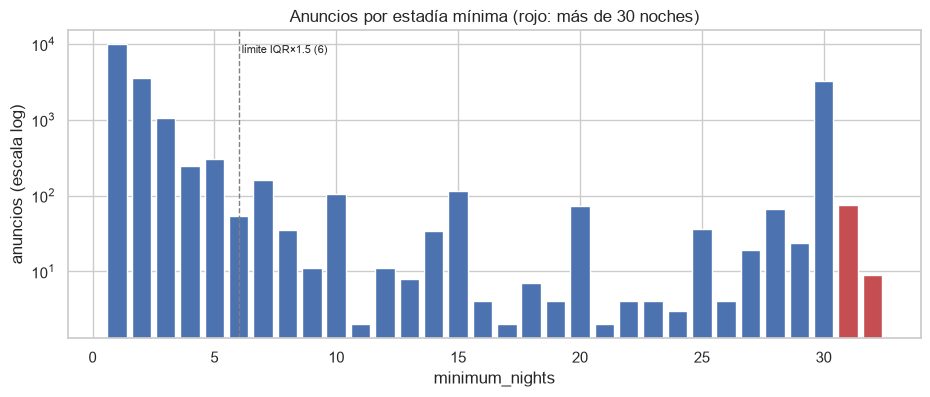

In [20]:
minimo = pd.to_numeric(listings["minimum_nights"], errors="coerce")
display(minimo.describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("minimum_nights"))
q1_m, q3_m = minimo.quantile([0.25, 0.75])
limite_iqr_m = q3_m + 1.5 * (q3_m - q1_m)
print(f"IQR×1.5 marcaría > {limite_iqr_m:g} noches: {(minimo > limite_iqr_m).sum():,} anuncios ({(minimo > limite_iqr_m).mean():.1%})")
print(f"Regla de negocio > {UMBRAL_MINIMO_NOCHES} noches: {(minimo > UMBRAL_MINIMO_NOCHES).sum():,} anuncios")

fig, ax = plt.subplots(figsize=(11, 4))
frecuencias = minimo.value_counts().sort_index()
ax.bar(frecuencias.index, frecuencias.values, color=np.where(frecuencias.index > UMBRAL_MINIMO_NOCHES, "#C44E52", "#4C72B0"))
ax.set_yscale("log")
ax.axvline(limite_iqr_m, color="gray", ls="--", lw=1)
ax.text(limite_iqr_m, ax.get_ylim()[1] * 0.5, f" límite IQR×1.5 ({limite_iqr_m:g})", fontsize=8)
ax.set(title="Anuncios por estadía mínima (rojo: más de 30 noches)", xlabel="minimum_nights", ylabel="anuncios (escala log)")
guardar(fig, "03_minimum_nights")
plt.show()

**Interpretación.** La estadía mínima se concentra en 1 a 3 noches (mediana 1, Q3 = 3), con un segundo grupo en 30 noches (P95 = 30).
Como Q1 y Q3 están tan juntos, el criterio IQR marcaría todo lo que pase de 6 noches: 4 053 anuncios (21 %), lo que no es un “atípico”
sino un segmento (las estadías mensuales vistas arriba).
**Decisión:** se usa una regla de negocio, `minimum_nights > 30` (estadías de más de un mes, ≈84 anuncios, máximo 32), y se marca
en `minimo_noches_atipico` sin eliminar.

### Atípicos en `availability_365`

,availability_365
count,"19,187.00"
mean,306.95
std,82.07
min,0.00
25%,269.00
50%,349.00
75%,363.00
max,365.00


Fuera del rango 0-365: 0
Disponibles los 365 días: 3,508 · con 0 días: 4


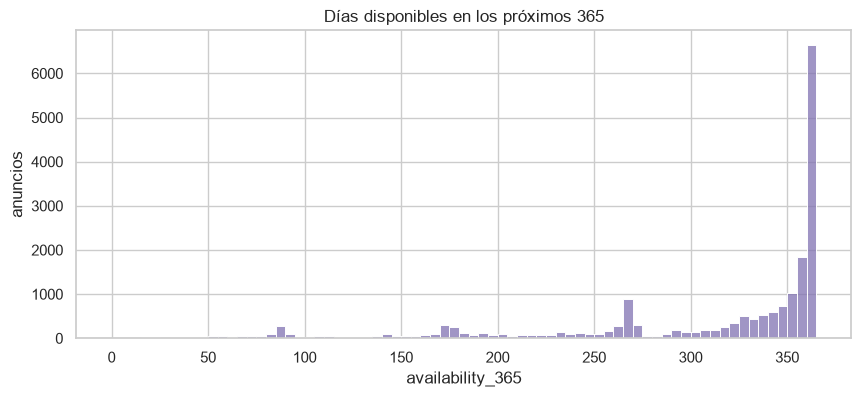

In [21]:
disponibilidad = pd.to_numeric(listings["availability_365"], errors="coerce")
display(disponibilidad.describe().to_frame("availability_365"))
print(f"Fuera del rango 0-365: {((disponibilidad < 0) | (disponibilidad > 365)).sum():,}")
print(f"Disponibles los 365 días: {(disponibilidad == 365).sum():,} · con 0 días: {(disponibilidad == 0).sum():,}")

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(disponibilidad, bins=73, ax=ax, color="#8172B2")
ax.set(title="Días disponibles en los próximos 365", xlabel="availability_365", ylabel="anuncios")
guardar(fig, "04_availability_365")
plt.show()

**Interpretación.** Todos los valores están dentro de 0–365, así que no hay errores de rango. La distribución está cargada a la
derecha (mediana ≈349): la mayoría de anuncios tiene casi todo el año libre en el calendario, y ≈3 508 están disponibles los 365 días,
lo que suele indicar anuncios poco activos o con calendario sin actualizar, no ocupación real. Los 4 anuncios con 0 días pueden estar
pausados. **Decisión:** no se eliminan; el ETL solo valida el rango 0–365 (un valor fuera de él se volvería nulo y quedaría en el log).

### Calidad del texto en reseñas

In [22]:
comentarios = reviews["comments"].astype("string") if "comments" in reviews.columns else pd.Series(dtype="string")
calidad_texto = pd.Series({
    "reseñas sin comentario": int(comentarios.isna().sum() + (comentarios.str.strip() == "").sum()),
    "comentarios con <br/>": int(comentarios.str.contains(r"<\s*br\s*/?\s*>", case=False, regex=True, na=False).sum()),
    "comentarios con \\r": int(comentarios.str.contains("\r", regex=False, na=False).sum()),
    "comentarios con espacios repetidos": int(comentarios.str.contains(r"\s{2,}", regex=True, na=False).sum()),
}, name="reseñas")
display(calidad_texto.to_frame())
ejemplo = comentarios[comentarios.str.contains("<br", na=False)].iloc[0] if calidad_texto["comentarios con <br/>"] else ""
posicion = max(ejemplo.find("<br") - 60, 0)
fragmento = ejemplo[posicion:posicion + 140]
print("Antes:  ", repr(fragmento))
print("Después:", repr(limpiar_texto(pd.Series([fragmento])).iloc[0]))

,reseñas
reseñas sin comentario,191
comentarios con <br/>,69375
comentarios con \r,800
comentarios con espacios repetidos,47748


Antes:   ' very safe area. I felt safe walking in the area at night. \r<br/>\r<br/>Marcela is very nice and is fluent in both Spanish and English. She i'
Después: 'very safe area. I felt safe walking in the area at night. Marcela is very nice and is fluent in both Spanish and English. She i'


**Interpretación.** 69 375 comentarios traen etiquetas HTML `<br/>`, 800 retornos de carro `\r` y 47 748 espacios repetidos, restos
del formulario web.
Además de ensuciar el texto, algunos caracteres de control hacen fallar la escritura en Excel. **Decisión:** `limpiar_texto()`
reemplaza `<br/>` por espacio, elimina caracteres de control y espacios repetidos (se ve el antes/después arriba).

### Calendar: días por mes y valores centinela

In [23]:
dias_por_mes = calendar_mensual.groupby("mes").agg(anuncios=("listing_id", "nunique"),
                                                   dias_promedio=("dias_registrados", "mean"))
display(dias_por_mes)
print("Valores de 'available' en la muestra diaria:", calendar_muestra["available"].value_counts().to_dict())
if "maximum_nights" in calendar_muestra.columns:
    maximo = pd.to_numeric(calendar_muestra["maximum_nights"], errors="coerce")
    print(f"maximum_nights máximo en la muestra: {maximo.max():,.0f}; "
          f"filas con valores > 3 650 (10 años): {(maximo > 3650).sum():,}")

,anuncios,dias_promedio
mes,,
2026-06,19187,9.08
2026-07,19187,31.00
2026-08,19187,31.00
2026-09,19187,30.00
2026-10,19187,31.00
2026-11,19187,30.00
2026-12,19187,31.00
2027-01,19187,31.00
2027-02,19187,28.00


Valores de 'available' en la muestra diaria: {'t': 165950, 'f': 34050}
maximum_nights máximo en la muestra: 1,241,244; filas con valores > 3 650 (10 años): 365


**Interpretación.** El calendario cubre 365 días desde el 21-jun-2026, así que **junio de 2026 y junio de 2027 son meses parciales**
(≈9 y ≈21 días por anuncio): sumar días disponibles por mes sin tenerlo en cuenta haría parecer que esos meses tienen menos oferta.
**Decisión:** el ETL calcula `pct_disponibilidad` (proporción, no suma) y agrega la bandera `mes_completo`.
En la muestra diaria el mayor `maximum_nights` es 1 241 244 noches (3 400 años); en la colección completa hay 1 823 filas por encima de
10 años y el máximo es 2 147 483 647, el mayor entero de 32 bits: es un **centinela** de “sin límite”, no un dato. En la variante diaria
del ETL esos valores se convierten en nulo.

## 2.3 Transformaciones necesarias

### Moneda: `price` de texto a número

In [24]:
patron_precio = r"^\$\d{1,3}(,\d{3})*\.\d{2}$"
texto_precio = listings["price"].dropna().astype("string")
print(f"Precios con el formato '$#,###.##': {texto_precio.str.match(patron_precio).sum():,} de {len(texto_precio):,}")
pd.DataFrame({"texto en MongoDB": texto_precio.head(5).values,
              "numérico tras limpiar_precio()": limpiar_precio(texto_precio.head(5)).values})

Precios con el formato '$#,###.##': 18,992 de 18,992


,texto en MongoDB,numérico tras limpiar_precio()
0,"$284,294.01","284,294.01"
1,"$215,000.00","215,000.00"
2,"$99,196.10","99,196.10"
3,"$179,910.67","179,910.67"
4,"$82,260.75","82,260.75"


**Interpretación.** Todos los precios siguen el formato en inglés (punto decimal, coma de miles). Eso permite quitar `$` y `,` y
convertir a `float` sin ambigüedad; si apareciera otro formato, `limpiar_precio()` devuelve nulo y el ETL lo registra como advertencia.
La moneda es COP en todos los casos (el dataset es de Bogotá), por lo que no hay que convertir divisas.

### Fechas: formato `YYYY-MM-DD`

In [25]:
patron_fecha = r"^\d{4}-\d{2}-\d{2}$"
fuentes_fecha = {f"listings.{c}": listings[c] for c in existentes(listings, ["last_scraped", "first_review", "last_review", "calendar_last_scraped"])}
fuentes_fecha["reviews.date"] = reviews["date"]
fuentes_fecha["calendar.date"] = calendar_muestra["date"]
filas = []
for nombre, serie in fuentes_fecha.items():
    texto = serie.dropna().astype("string")
    convertidas = pd.to_datetime(texto, errors="coerce")
    filas.append({"columna": nombre, "con valor": len(texto), "formato ISO": int(texto.str.match(patron_fecha).sum()),
                  "inválidas": int(convertidas.isna().sum()), "mínima": convertidas.min(), "máxima": convertidas.max()})
pd.DataFrame(filas).set_index("columna")

,con valor,formato ISO,inválidas,mínima,máxima
columna,,,,,
listings.last_scraped,19187,19187,0,2026-06-21,2026-06-22
listings.first_review,14922,14922,0,2010-10-06,2026-06-21
listings.last_review,14922,14922,0,2011-10-14,2026-06-21
listings.calendar_last_scraped,19187,19187,0,2026-06-21,2026-06-22
reviews.date,527731,527731,0,2010-10-06,2026-06-21
calendar.date,200000,200000,0,2026-06-21,2027-06-21


**Interpretación.** Las fechas llegan como texto ISO y todas son convertibles, pero siguen siendo texto: no se pueden ordenar por
mes ni agrupar por trimestre. **Decisión:** se convierten con `pd.to_datetime(errors="coerce")`, se guardan como `YYYY-MM-DD` y de
`date` se derivan `anio`, `mes`, `dia` y `trimestre` (requisito del enunciado). Una fecha inválida se descarta y queda en el log.
Las reseñas van de octubre de 2010 a junio de 2026.

### Texto y booleanos

In [26]:
booleanas = existentes(listings, ["host_is_superhost", "host_has_profile_pic", "host_identity_verified",
                                  "has_availability", "instant_bookable"])
display(pd.DataFrame({c: listings[c].value_counts(dropna=False) for c in booleanas}).fillna(0).astype(int))
if "description" in listings.columns:
    descripcion = listings["description"].astype("string")
    print(f"Descripciones con <br/>: {descripcion.str.contains('<br', na=False).sum():,} de {descripcion.notna().sum():,}")
display(listings["room_type"].value_counts().to_frame("anuncios"))

,host_is_superhost,host_has_profile_pic,host_identity_verified,has_availability
f,12877,687,319,0
t,6310,18500,18868,19057
NaN,0,0,0,130


Descripciones con <br/>: 8,045 de 18,664


,anuncios
room_type,
Entire home/apt,13865
Private room,5172
Shared room,117
Hotel room,33


**Interpretación.** Los booleanos están codificados como `"t"`/`"f"`; se convierten a 1/0 para poder sumarlos y promediarlos
(p. ej. % de superanfitriones). Las descripciones también traen `<br/>`. `room_type` tiene solo 4 categorías limpias
(Entire home/apt ≈13 865, Private room ≈5 172, Shared room ≈117, Hotel room ≈33), así que no requiere recodificación.

### Campo anidado: `amenities`

amenities parseados como JSON: 19,187 de 19,187 (fallidos: 0)
Relaciones anuncio-servicio: 505,595 · servicios distintos: 3,588
Servicios por anuncio: media 26.4, mediana 26, máximo 90
Ejemplo crudo: ["Blender", "Luggage dropoff allowed", "Long term stays allowed", "Children\u2019s dinnerware", "Drying rack for clothing", "Free parking on premises" ...


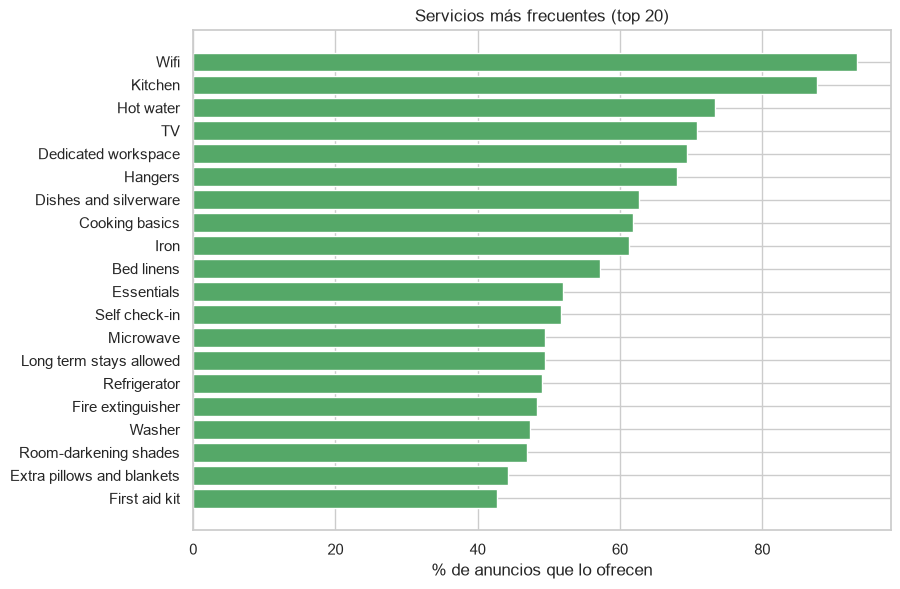

In [27]:
parseados = listings["amenities"].map(parsear_amenities) if "amenities" in listings.columns else pd.Series(dtype=object)
listas = parseados.map(lambda t: t[0])
fallidos = (~parseados.map(lambda t: t[1])).sum()
n_amenities = listas.map(len)
amenities_largo = listas.explode().dropna()
print(f"amenities parseados como JSON: {len(parseados) - fallidos:,} de {len(parseados):,} (fallidos: {fallidos:,})")
print(f"Relaciones anuncio-servicio: {len(amenities_largo):,} · servicios distintos: {amenities_largo.nunique():,}")
print(f"Servicios por anuncio: media {n_amenities.mean():.1f}, mediana {n_amenities.median():.0f}, máximo {n_amenities.max()}")
print("Ejemplo crudo:", str(listings["amenities"].dropna().iloc[0])[:150], "...")

top_amenities = amenities_largo.value_counts().head(20)
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top_amenities.index[::-1], 100 * top_amenities.values[::-1] / len(listings), color="#55A868")
ax.set(title="Servicios más frecuentes (top 20)", xlabel="% de anuncios que lo ofrecen")
guardar(fig, "05_top_amenities")
plt.show()

**Interpretación.** `amenities` es una lista JSON guardada como texto (con escapes como `\u2019`), con ≈26 servicios por anuncio y
≈3 588 servicios distintos. Así no se puede responder “¿cuántos anuncios tienen wifi?” sin parsear el texto cada vez.
**Decisión:** se desanida en una tabla larga `listing_amenities (listing_id, amenity)` (≈505 mil filas) y se agrega `n_amenities`
al anuncio. Los servicios básicos (wifi, cocina, agua caliente) están en casi todos los anuncios y no diferencian la oferta; los que
están en una fracción menor son los útiles para segmentar.

### Información del anfitrión

16 columnas del anfitrión repetidas en cada anuncio: host_id, host_url, host_profile_id, host_profile_url, host_name, hosts_time_as_user_years, hosts_time_as_user_months, hosts_time_as_host_years, hosts_time_as_host_months, host_location, host_about, host_is_superhost, host_picture_url, host_listings_count, host_has_profile_pic, host_identity_verified
Anfitriones únicos: 8,335 para 19,187 anuncios
Anfitriones con datos distintos entre sus anuncios: 0


,anfitriones,anuncios,% de anuncios
1,5961,5961,31.07
2,997,1994,10.39
3-5,794,2951,15.38
6-10,328,2455,12.80
11-50,238,4454,23.21
más de 50,17,1372,7.15


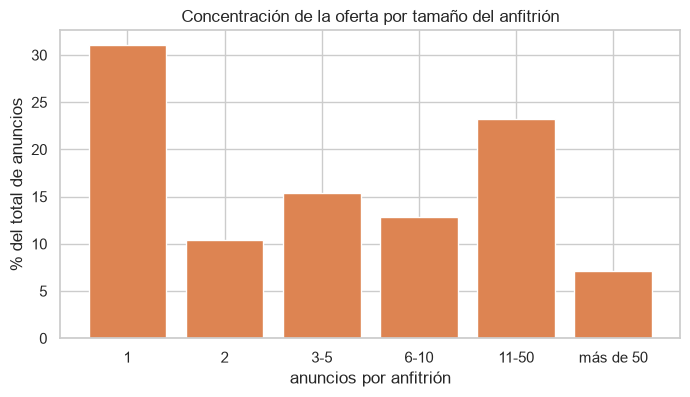

In [28]:
columnas_host = [c for c in listings.columns if c.startswith(("host_", "hosts_"))]
print(f"{len(columnas_host)} columnas del anfitrión repetidas en cada anuncio:", ", ".join(columnas_host))
anuncios_por_host = listings.groupby("host_id").size()
inconsistentes = (listings.groupby("host_id")[[c for c in columnas_host if c != "host_id"]]
                          .nunique(dropna=False).max(axis=1) > 1).sum()
print(f"Anfitriones únicos: {listings['host_id'].nunique():,} para {len(listings):,} anuncios")
print(f"Anfitriones con datos distintos entre sus anuncios: {inconsistentes:,}")

grupos = pd.cut(anuncios_por_host, [0, 1, 2, 5, 10, 50, np.inf], labels=["1", "2", "3-5", "6-10", "11-50", "más de 50"])
resumen_hosts = pd.DataFrame({"anfitriones": grupos.value_counts(sort=False),
                              "anuncios": anuncios_por_host.groupby(grupos, observed=False).sum()})
resumen_hosts["% de anuncios"] = 100 * resumen_hosts["anuncios"] / resumen_hosts["anuncios"].sum()
display(resumen_hosts)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(resumen_hosts.index.astype(str), resumen_hosts["% de anuncios"], color="#DD8452")
ax.set(title="Concentración de la oferta por tamaño del anfitrión", xlabel="anuncios por anfitrión", ylabel="% del total de anuncios")
guardar(fig, "06_anuncios_por_anfitrion")
plt.show()

**Interpretación.** Los datos del anfitrión no están anidados en un subdocumento, pero sus 16 columnas se repiten en cada anuncio:
8 335 anfitriones para 19 187 anuncios, y ningún anfitrión tiene datos contradictorios entre sus anuncios (separarlos no pierde
información). Solo el 31 % de los anuncios pertenece a anfitriones con un único anuncio; el **30 % está en manos de anfitriones con más
de 10** (17 anfitriones tienen más de 50 anuncios y suman 1 372): buena parte de la oferta la manejan operadores profesionales. **Decisión:** las columnas `host_*` se separan en una tabla `hosts` (una fila por `host_id`) y `listings`
conserva solo `host_id` como llave foránea; así se evita la redundancia y se puede analizar al anfitrión como entidad.

### Calendario agrupado por mes y por semana

,dias_disponibles,dias_registrados,pct_disponible,mes_completo
mes,,,,
2026-06,106810,174141,61.34,False
2026-07,456400,594797,76.73,True
2026-08,515099,594797,86.60,True
2026-09,511507,575610,88.86,True
2026-10,511561,594797,86.01,True
2026-11,518575,575610,90.09,True
2026-12,530084,594797,89.12,True
2027-01,527871,594797,88.75,True
2027-02,478752,537236,89.11,True


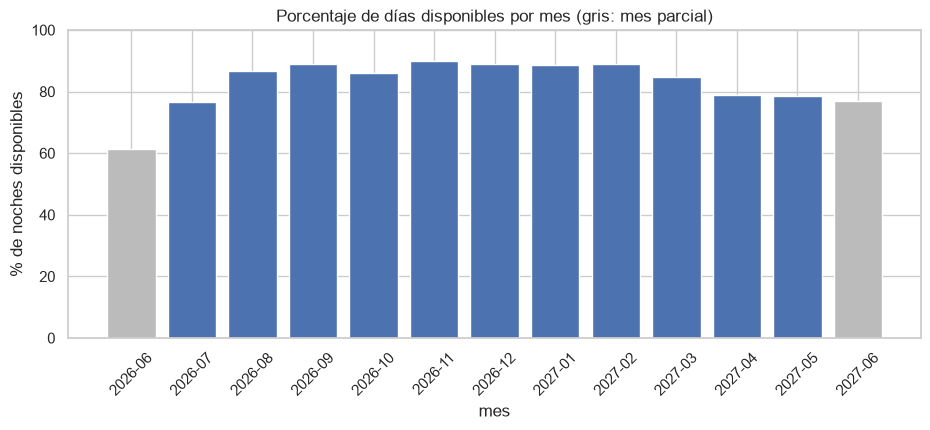

In [29]:
mensual = (calendar_mensual.groupby("mes")[["dias_disponibles", "dias_registrados"]].sum()
                           .assign(pct_disponible=lambda d: 100 * d["dias_disponibles"] / d["dias_registrados"]))
dias_por_anuncio = calendar_mensual.groupby("mes")["dias_registrados"].max()
mensual["mes_completo"] = dias_por_anuncio >= 28
display(mensual)

fig, ax = plt.subplots(figsize=(11, 4))
colores = np.where(mensual["mes_completo"], "#4C72B0", "#BBBBBB")
ax.bar(mensual.index, mensual["pct_disponible"], color=colores)
ax.set(title="Porcentaje de días disponibles por mes (gris: mes parcial)", xlabel="mes", ylabel="% de noches disponibles")
ax.set_ylim(0, 100)
plt.setp(ax.get_xticklabels(), rotation=45)
guardar(fig, "07_disponibilidad_mensual")
plt.show()

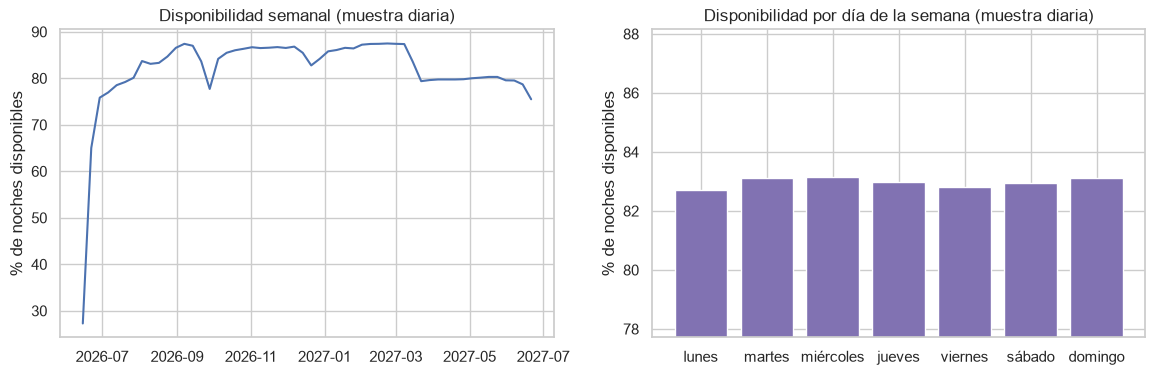

In [30]:
diario = calendar_muestra.assign(fecha=pd.to_datetime(calendar_muestra["date"], errors="coerce"),
                                 disponible=calendar_muestra["available"].astype("string").isin(["t", "True", "true"]))
dias = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
por_dia = diario.groupby(diario["fecha"].dt.dayofweek)["disponible"].mean().mul(100).rename(index=dict(enumerate(dias)))
semanal = diario.groupby(diario["fecha"].dt.to_period("W").dt.start_time)["disponible"].mean().mul(100)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(semanal.index, semanal.values, color="#4C72B0")
axes[0].set(title="Disponibilidad semanal (muestra diaria)", ylabel="% de noches disponibles")
axes[1].bar(por_dia.index, por_dia.values, color="#8172B2")
axes[1].set(title="Disponibilidad por día de la semana (muestra diaria)", ylabel="% de noches disponibles")
axes[1].set_ylim(por_dia.min() - 5, min(100, por_dia.max() + 5))
guardar(fig, "08_disponibilidad_semanal")
plt.show()

**Interpretación.** El calendario diario tiene 7 millones de filas, pero la pregunta de negocio (“¿qué tan disponible está la oferta en
cada mes?”) se responde con 13 filas por anuncio. **Decisión:** el agrupamiento por anuncio y mes se hace **dentro de MongoDB**
(`$group`), lo que reduce a 249 431 filas lo que viaja a pandas; por eso el log del ETL registra 249 431 registros extraídos de
Calendar y no 7 millones. Los meses cercanos son los menos disponibles (julio 2026: 77 %, porque ya hay reservas); entre septiembre de 2026
y febrero de 2027 la disponibilidad se estabiliza en 86–90 %, y vuelve a bajar a ≈79 % entre marzo y junio de 2027. Esa caída lejana no
son reservas: muchos anfitriones bloquean las fechas más alejadas del calendario, así que la disponibilidad lejana no debe leerse como
demanda. La disponibilidad por día de la semana es prácticamente igual todos los días (≈83 %, muestra de ≈548 anuncios): en esta muestra
no hay efecto de fin de semana.

### Rangos de precio

,anuncios,%,límite superior (COP)
price,,,
Económico,4754,24.78,"110,000.00"
Bajo,4649,24.23,"160,000.00"
Medio,4832,25.18,"230,000.00"
Alto,3822,19.92,"500,000.00"
Premium,935,4.87,inf
Sin precio,195,1.02,NaN


Percentiles reales P25/P50/P75/P95: ['$110,000', '$161,460', '$230,346', '$497,580']


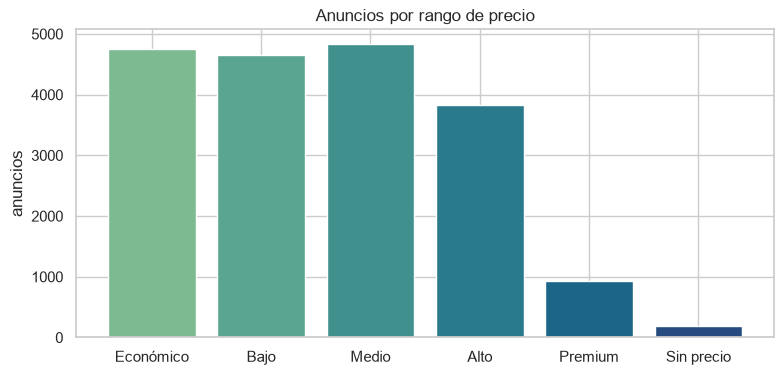

In [31]:
rango = pd.cut(precio, bins=PRECIO_CORTES, labels=PRECIO_ETIQUETAS, include_lowest=True)
rango = rango.cat.add_categories("Sin precio").fillna("Sin precio")
tabla_rangos = rango.value_counts().reindex(PRECIO_ETIQUETAS + ["Sin precio"]).to_frame("anuncios")
tabla_rangos["%"] = 100 * tabla_rangos["anuncios"] / len(rango)
tabla_rangos["límite superior (COP)"] = PRECIO_CORTES[1:] + [np.nan]
display(tabla_rangos)
print("Percentiles reales P25/P50/P75/P95:", [f"${v:,.0f}" for v in precio.quantile([0.25, 0.5, 0.75, 0.95])])

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(tabla_rangos.index, tabla_rangos["anuncios"], color=sns.color_palette("crest", len(tabla_rangos)))
ax.set(title="Anuncios por rango de precio", ylabel="anuncios")
guardar(fig, "09_rangos_precio")
plt.show()

**Interpretación.** Los cortes (110 000 · 160 000 · 230 000 · 500 000 COP) están alineados con los percentiles 25, 50, 75 y 95
redondeados (P25 110 000 · P50 161 460 · P75 230 346 · P95 497 580): Económico, Bajo y Medio quedan con ≈25 % de los anuncios cada uno,
Alto con ≈20 % y Premium con el 5 % superior (935). Son cifras redondas fáciles de comunicar y no dependen de que el atípico de 448 millones exista o no.
**Decisión:** se mantienen los cortes de `src/config.py` (`PRECIO_CORTES`); los 195 anuncios sin precio van en `"Sin precio"`.

## 2.4 Hallazgos

### Correlaciones

Se usa **Spearman** (por rangos) porque el precio es muy asimétrico y tiene atípicos extremos: Pearson quedaría dominado por unos
pocos valores. Spearman equivale a medir la relación monótona, sin suponer linealidad.

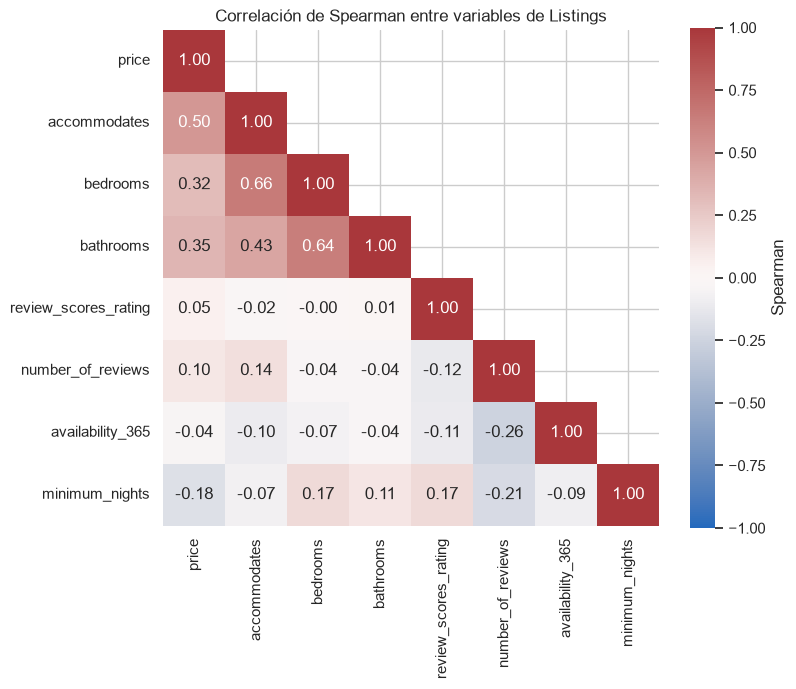

,Spearman con price
accommodates,0.50
bathrooms,0.35
bedrooms,0.32
number_of_reviews,0.10
review_scores_rating,0.05
availability_365,-0.04
minimum_nights,-0.18


In [32]:
variables = existentes(listings, ["precio_num", "accommodates", "bedrooms", "bathrooms", "review_scores_rating",
                                  "number_of_reviews", "availability_365", "minimum_nights"])
numericas = listings[variables].apply(pd.to_numeric, errors="coerce").rename(columns={"precio_num": "price"})
correlacion = numericas.corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6.5))
mascara = np.triu(np.ones_like(correlacion, dtype=bool), k=1)
sns.heatmap(correlacion, mask=mascara, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Spearman"})
ax.set_title("Correlación de Spearman entre variables de Listings")
guardar(fig, "10_correlaciones")
plt.show()
correlacion["price"].drop("price").sort_values(ascending=False).to_frame("Spearman con price")

**Interpretación.** El precio se relaciona sobre todo con el **tamaño** del alojamiento: `accommodates` (0,50), `bathrooms` (0,35) y
`bedrooms` (0,32), que además están correlacionadas entre sí porque miden casi lo mismo. La calificación (0,05), el número de reseñas
(0,10) y la disponibilidad (−0,04) casi no se relacionan con el precio: en Bogotá el precio lo explica la capacidad más que la reputación.
`minimum_nights` tiene relación negativa (−0,18) por el descuento de las estadías mensuales. `number_of_reviews` y `availability_365` se
mueven en sentido contrario (−0,26): los anuncios con más reseñas tienen menos noches libres, coherente con que una disponibilidad alta
indica poca demanda o calendarios inactivos.

### Precio por tipo de habitación y por localidad

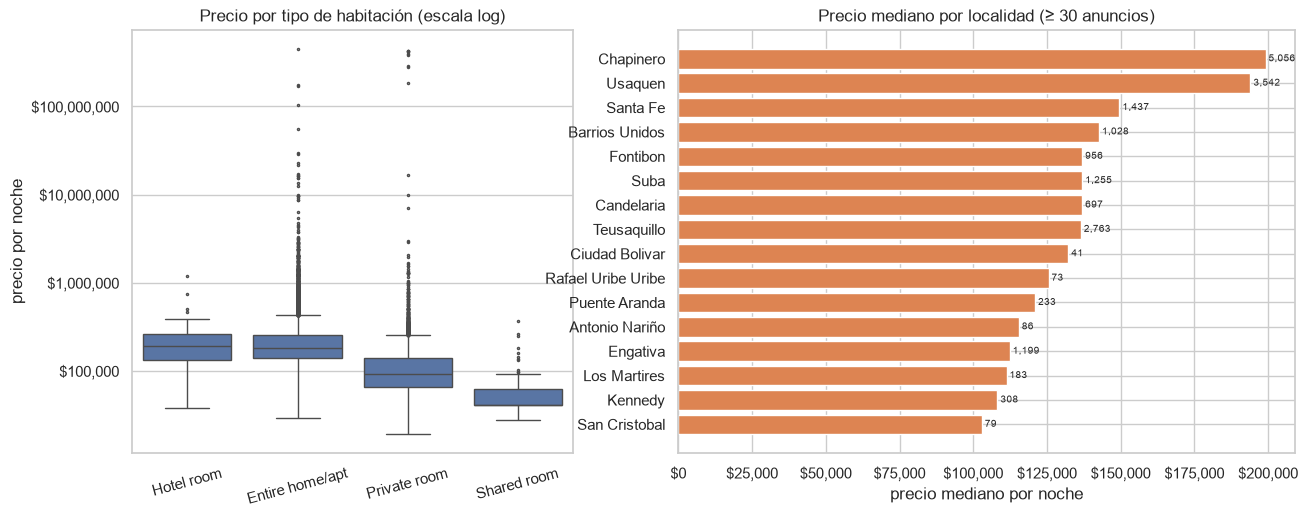

,count,50%,mean
room_type,,,
Entire home/apt,"13,744.00","182,589.00","333,541.96"
Hotel room,33.00,"193,048.00","253,385.40"
Private room,"5,098.00","91,295.00","759,384.92"
Shared room,117.00,"41,453.00","60,082.24"


In [33]:
con_precio = listings[precio.notna()].copy()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})
orden_tipos = con_precio.groupby("room_type")["precio_num"].median().sort_values(ascending=False).index
sns.boxplot(data=con_precio, x="room_type", y="precio_num", order=orden_tipos, ax=axes[0], fliersize=1.5, color="#4C72B0")
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(COP)
axes[0].set(title="Precio por tipo de habitación (escala log)", xlabel="", ylabel="precio por noche")
axes[0].tick_params(axis="x", rotation=15)

if "neighbourhood_cleansed" in con_precio.columns:
    por_barrio = (con_precio.groupby("neighbourhood_cleansed")["precio_num"]
                            .agg(anuncios="size", mediana="median").query("anuncios >= 30")
                            .sort_values("mediana"))
    axes[1].barh(por_barrio.index, por_barrio["mediana"], color="#DD8452")
    axes[1].xaxis.set_major_formatter(COP)
    axes[1].set(title="Precio mediano por localidad (≥ 30 anuncios)", xlabel="precio mediano por noche")
    for y, n in enumerate(por_barrio["anuncios"]):
        axes[1].text(por_barrio["mediana"].iloc[y], y, f" {n:,}", va="center", fontsize=7)
guardar(fig, "11_precio_tipo_localidad")
plt.show()
con_precio.groupby("room_type")["precio_num"].describe(percentiles=[0.5])[["count", "50%", "mean"]]

**Interpretación.** El alojamiento completo domina la oferta (13 744 anuncios con precio) con mediana de 182 589 COP; la habitación
privada cuesta la mitad (91 295) y la compartida 41 453. La habitación de hotel tiene la mediana más alta (193 048), pero son solo 33
anuncios. La media de la habitación privada (759 385) es ocho veces su mediana por los anuncios erróneos de “casa Q Iuniq”: por eso los
resúmenes usan **mediana**. Por localidad, Chapinero (199 112 COP, 5 056 anuncios con precio) y Usaquén (194 001, 3 542) concentran la oferta y los
precios más altos; Kennedy (108 207) y San Cristóbal (102 901) están entre las más económicas. El número junto a cada barra es la cantidad
de anuncios, para no sobreinterpretar localidades con poca oferta.

### Reseñas en el tiempo

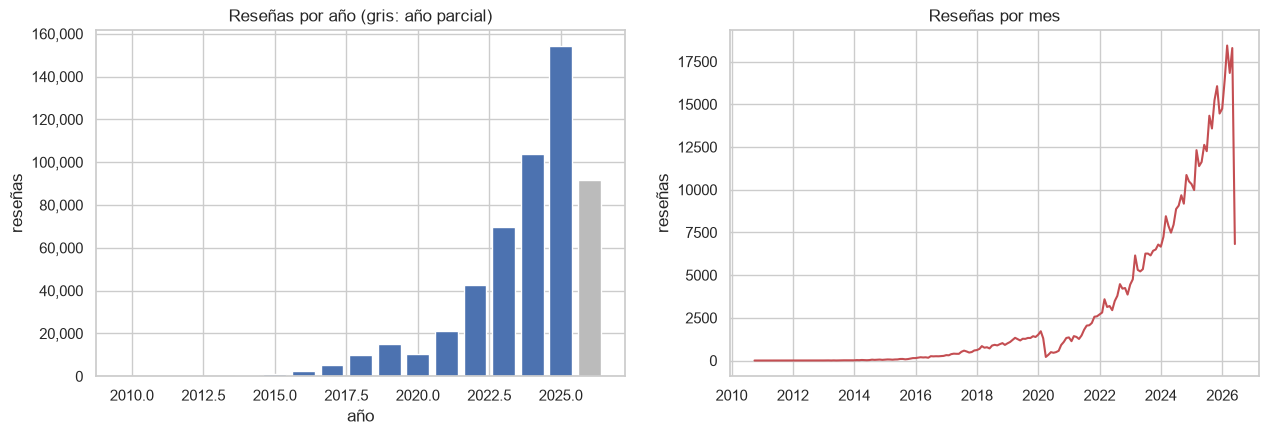

Reseñas por anuncio con reseñas: mediana 15, máximo 6,162


In [34]:
fechas_resenas = pd.to_datetime(reviews["date"], errors="coerce")
por_anio = fechas_resenas.dt.year.value_counts().sort_index()
por_mes = fechas_resenas.dt.to_period("M").value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(por_anio.index.astype(int), por_anio.values, color=np.where(por_anio.index == fechas_resenas.max().year, "#BBBBBB", "#4C72B0"))
axes[0].set(title="Reseñas por año (gris: año parcial)", xlabel="año", ylabel="reseñas")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
axes[1].plot(por_mes.index.to_timestamp(), por_mes.values, color="#C44E52")
axes[1].set(title="Reseñas por mes", ylabel="reseñas")
guardar(fig, "12_resenas_tiempo")
plt.show()

resenas_por_anuncio = reviews.groupby("listing_id").size()
print(f"Reseñas por anuncio con reseñas: mediana {resenas_por_anuncio.median():.0f}, máximo {resenas_por_anuncio.max():,}")

**Interpretación.** Las reseñas sirven como aproximación de la demanda: crecen cada año hasta 2019 (15 051), caen 31 % en 2020 por la
pandemia (10 393) y desde 2021 crecen con fuerza hasta 154 156 en 2025, diez veces lo de 2019. 2026 está incompleto (los datos terminan el
21 de junio) y aun así ya suma 91 608; por eso se marca en gris: no es una caída de demanda. La distribución por anuncio es muy desigual
(mediana de 15 reseñas, máximo 6 162).

### Verificación: la clase `Transformacion` sobre lo extraído

Se aplica la clase del ETL a los mismos DataFrames para comprobar que produce lo que el EDA justificó (sin cargar nada).

In [35]:
from src.transformacion import Transformacion

tablas = Transformacion().ejecutar({"listings": listings.drop(columns=["precio_num", "noches_cotizadas"], errors="ignore"),
                                    "reviews": reviews, "calendar_mensual": calendar_mensual})
display(pd.DataFrame({"filas": {n: len(t) for n, t in tablas.items()}, "columnas": {n: t.shape[1] for n, t in tablas.items()}}))
lt = tablas["listings"]
print("rango_precio:", lt["rango_precio"].value_counts().to_dict())
print("precio_atipico:", int(lt["precio_atipico"].sum()), "· minimo_noches_atipico:", int(lt["minimo_noches_atipico"].sum()))
maximo_id = lt["listing_id"].max()
print(f"listing_id máximo: {maximo_id:,} →", "supera 15 dígitos: Excel lo redondearía, por eso los IDs se exportan como texto"
      if maximo_id > 9e15 else "cabe en 15 dígitos")

2026-10-11 22:00:47 | INFO    | etl_airbnb.transformacion | === Inicio de la transformación ===


2026-10-11 22:00:47 | INFO    | etl_airbnb.transformacion | Transformación de Listings: 19,187 filas, 77 columnas de entrada


2026-10-11 22:00:47 | INFO    | etl_airbnb.transformacion | Sin listing_id duplicados


2026-10-11 22:00:47 | INFO    | etl_airbnb.transformacion | Deduplicación de Listings: 19,187 registros antes, 19,187 después (0 eliminados)


2026-10-11 22:00:47 | INFO    | etl_airbnb.transformacion | Se descartan columnas redundantes (payload JSON ya extraído en otras columnas): ['price_quote_raw']


...

2026-10-11 22:00:57 | INFO    | etl_airbnb.transformacion | Deduplicación de calendario mensual: 249,431 registros antes, 249,431 después (0 eliminados)


2026-10-11 22:00:57 | INFO    | etl_airbnb.transformacion | Calendario mensual: 249,431 filas; 38,374 corresponden a meses parciales (bordes del rango)


2026-10-11 22:00:57 | INFO    | etl_airbnb.transformacion | === Fin de la transformación: listings=19,187, hosts=8,335, listing_amenities=505,595, reviews=527,731, calendario_mensual=249,431 ===


,filas,columnas
listings,19187,65
hosts,8335,16
listing_amenities,505595,2
reviews,527731,12
calendario_mensual,249431,11


rango_precio: {'Medio': 4832, 'Económico': 4754, 'Bajo': 4649, 'Alto': 3822, 'Premium': 935, 'Sin precio': 195}
precio_atipico: 659 · minimo_noches_atipico: 84
listing_id máximo: 1,712,443,307,406,192,155 → supera 15 dígitos: Excel lo redondearía, por eso los IDs se exportan como texto


### Resumen de hallazgos y decisiones para la transformación

| Hallazgo (sección) | Decisión en `src/transformacion.py` / `src/carga.py` |
|---|---|
| 13 columnas 100 % vacías (2.2) | Se descartan; además no existen en MongoDB |
| `review_scores_*`, `bedrooms`, `bathrooms` nulos estructurales (2.2) | No se imputan |
| `host_about`, `host_location`, `description` vacíos (2.2) | Se rellenan con `"Sin información"` |
| 195 anuncios sin precio (2.2) | Se conservan con `rango_precio = "Sin precio"` (opción `--eliminar-sin-precio`) |
| Sin duplicados ni huérfanos (2.2) | Deduplicación por llave y filtro de integridad como control, con WARNING en el log |
| Precio con cola extrema, máximo 448 M (2.2) | `precio_atipico` por IQR×3 (≈659); se marca, no se elimina |
| `minimum_nights` concentrado en 1–3 (2.2) | Regla de negocio `> 30` noches (≈84) en vez de IQR |
| `availability_365` dentro de 0–365 (2.2) | Solo validación de rango |
| `price` como texto `"$#,###.##"` (2.3) | `limpiar_precio()` → `float` |
| Fechas como texto ISO (2.3) | `datetime` → `YYYY-MM-DD` + `anio`, `mes`, `dia`, `trimestre` |
| `"t"`/`"f"`, `<br/>`, `\r`, espacios (2.2–2.3) | Booleanos 1/0; `limpiar_texto()` |
| `amenities` JSON en texto (2.3) | Tabla `listing_amenities` + `n_amenities` |
| Datos del anfitrión repetidos por anuncio (2.3) | Tabla `hosts` (1 fila por `host_id`) |
| Calendar de 7 M filas, meses parciales, centinela 2 147 483 647 (2.2–2.3) | Agregación mensual en MongoDB, `pct_disponibilidad`, `mes_completo`; centinela → nulo |
| Percentiles del precio 110k/161k/230k/498k (2.3) | Rangos Económico / Bajo / Medio / Alto / Premium |
| IDs de hasta 19 dígitos (2.4) | Se exportan como texto en XLSX (Excel solo conserva 15 dígitos) |
| 18 % de los precios son tarifas de estadía mensual con descuento (2.2) | Limitación documentada; se conservan `price_quote_*` y `minimum_nights` |
| Seis anuncios de un mismo anfitrión con precios de 388–448 millones (2.2) | Quedan marcados como `precio_atipico`; excluirlos de promedios |